# Cost-Aware Conformal Deferral Framework — Corrected Independent Evaluation

**Fix 3.2:** Select the deferral threshold exclusively on `step7_tuning_predictions.csv`, freeze the policy, and evaluate it on `step9_test_predictions.csv` without re-optimizing. Original historical notebook is preserved separately.

Policies: **No Deferral**, **Confidence-Only Deferral**, and **Conformal-Aware Deferral** (non-singleton sets include both empty and two-label sets).

All cost scenarios are explicitly labeled **(C_FN / C_FP / C_DEF)**. Results are preliminary until the full repeated-CV protocol is corrected and rerun.

## 1. Imports and run selection

Run from the corrected project root in PyCharm/Jupyter. The notebook discovers **only** `corrected_outputs` runs that contain both tuning and test CSVs, and selects the latest complete run per model by default. Set `RUN_IDS` explicitly to pin a run. Do not point this notebook at historical experiment directories.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
CORRECTED_ROOT = PROJECT_ROOT / "corrected_outputs"
if not CORRECTED_ROOT.is_dir():
    raise FileNotFoundError(f"Run this notebook from corrected project root: {CORRECTED_ROOT}")

MODEL_DIRS = {"RandomForest": "random_forest", "RUSBoost": "rusboost", "XGBoost": "xgboost"}
# Original model-training runs use 20/1/2; other cost scenarios are evaluated on the
# same frozen predictions, while clearly retaining the source training scenario.
TRAINING_SCENARIO = "20/1/2"
RUN_IDS = {"RandomForest": None, "RUSBoost": None, "XGBoost": None}
COST_SCENARIOS = {
    "10/1/1": {"c_fn": 10.0, "c_fp": 1.0, "c_def": 1.0},
    "20/1/2": {"c_fn": 20.0, "c_fp": 1.0, "c_def": 2.0},
    "30/1/5": {"c_fn": 30.0, "c_fp": 1.0, "c_def": 5.0},
}
TAU_GRID = np.linspace(0.50, 0.99, 100)
EVALUATION_RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_policy_eval"
OUTPUT_DIR = PROJECT_ROOT / "corrected_policy_outputs" / EVALUATION_RUN_ID
# Never reuse an existing output folder or overwrite historical results.
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
print("Evaluation run:", EVALUATION_RUN_ID)
print("Output directory:", OUTPUT_DIR)

Evaluation run: 20261115T190522567778Z_policy_eval
corrected_policy_outputs/20261115T190522567778Z_policy_eval


## 2. Helpers and leakage safeguards

A partition guard requires `partition=policy_tuning` for threshold optimization and `partition=test` for frozen evaluation. Source run IDs, seeds, row IDs, partition sizes and cost metadata must agree. **Do not remove these assertions.**

In [4]:
def locate_corrected_run(model_name):
    folder = MODEL_DIRS[model_name]
    base = CORRECTED_ROOT / folder / TRAINING_SCENARIO.replace("/", "_")
    candidates = []
    for path in base.glob(f"*/{folder}/pipeline_summary.json"):
        run_id = path.parent.parent.name
        if RUN_IDS[model_name] is not None and run_id != RUN_IDS[model_name]:
            continue
        required = ("step7_tuning_predictions.csv", "step9_test_predictions.csv")
        if all((path.parent / name).is_file() for name in required):
            candidates.append(path)
    if not candidates:
        raise FileNotFoundError(f"No complete corrected run for {model_name} under {base}")
    return sorted(candidates, key=lambda p: p.parent.parent.name)[-1]


def read_and_validate(model_name):
    summary_path = locate_corrected_run(model_name)
    summary = json.loads(summary_path.read_text())
    provenance = summary["provenance"]
    tuning = pd.read_csv(summary_path.parent / "step7_tuning_predictions.csv")
    testing = pd.read_csv(summary_path.parent / "step9_test_predictions.csv")
    expected = {"policy_tuning": tuning, "test": testing}
    for partition, frame in expected.items():
        assert len(frame) > 0, (model_name, partition)
        assert frame["partition"].eq(partition).all(), (model_name, partition)
        assert frame["run_id"].eq(provenance["run_id"]).all(), (model_name, "run_id")
        assert frame["random_seed"].eq(provenance["random_seed"]).all(), (model_name, "seed")
        assert frame["cost_scenario"].eq(provenance["cost_scenario"]).all(), (model_name, "cost")
        assert len(frame) == provenance["partition_stats"][partition]["size"]
        assert int(frame["y_true"].sum()) == provenance["partition_stats"][partition]["positive_count"]
        assert frame["row_id"].is_unique
        assert {"y_true", "p0", "p1", "certainty", "cp_set_size"}.issubset(frame.columns)
        assert np.allclose(frame["p0"] + frame["p1"], 1.0, atol=1e-6)
        assert np.allclose(frame["base_threshold"], provenance["base_threshold"], atol=1e-12)
        assert np.allclose(frame["q_alpha"], provenance["q_alpha"], atol=1e-12)
    assert set(tuning["row_id"]).isdisjoint(set(testing["row_id"])), model_name
    assert provenance["cost_scenario"] == TRAINING_SCENARIO
    return {"summary": summary, "provenance": provenance,
            "base_threshold": float(summary["step4_thresholding"]["base_threshold"]),
            "tuning_df": tuning, "test_df": testing, "source_summary": str(summary_path)}


def assert_partition(df, expected):
    assert "partition" in df.columns, "Missing partition tag"
    assert df["partition"].eq(expected).all(), f"Expected {expected}; refusing mismatched partition"


def evaluate_policy_from_df(df, base_threshold, tau, policy_name, c_fn, c_fp, c_def):
    """Pure policy scoring; only caller decides whether labels may be used for tuning."""
    y_true = df["y_true"].to_numpy(dtype=int)
    p1 = df["p1"].to_numpy(dtype=float)
    certainty = df["certainty"].to_numpy(dtype=float)
    cp_size = df["cp_set_size"].to_numpy(dtype=int)
    pred = (p1 >= base_threshold).astype(int)
    if policy_name == "No Deferral":
        deferred = np.zeros(len(df), dtype=bool)
    elif policy_name == "Confidence-Only Deferral":
        deferred = certainty < tau
    elif policy_name == "Conformal-Aware Deferral":
        deferred = (certainty < tau) | (cp_size != 1)
    else:
        raise ValueError(policy_name)
    retained = ~deferred
    fn = int(((pred == 0) & (y_true == 1) & retained).sum())
    fp = int(((pred == 1) & (y_true == 0) & retained).sum())
    tp = int(((pred == 1) & (y_true == 1) & retained).sum())
    tn = int(((pred == 0) & (y_true == 0) & retained).sum())
    deferred_count = int(deferred.sum())
    total_cost = c_fn * fn + c_fp * fp + c_def * deferred_count
    n_retained = int(retained.sum())
    positive_retained = int(((y_true == 1) & retained).sum())
    positive_predicted_retained = int(((pred == 1) & retained).sum())
    cp_covered = df["cp_covered"].to_numpy(dtype=int) if "cp_covered" in df else None
    return {
        "policy": policy_name, "tau": float(tau), "coverage": float(retained.mean()),
        "deferred_fraction": float(deferred.mean()), "retained_count": n_retained,
        "deferred_count": deferred_count,
        "retained_error": float((pred[retained] != y_true[retained]).mean()) if n_retained else np.nan,
        "retained_recall": float(tp / positive_retained) if positive_retained else np.nan,
        "retained_precision": float(tp / positive_predicted_retained) if positive_predicted_retained else np.nan,
        "fn": fn, "fp": fp, "tp": tp, "tn": tn,
        "total_cost": float(total_cost), "cost_per_sample": float(total_cost / len(df)),
        "conformal_coverage": float(cp_covered.mean()) if cp_covered is not None else np.nan,
        "failure_class_coverage": float(cp_covered[y_true == 1].mean()) if cp_covered is not None and (y_true == 1).any() else np.nan,
        "empty_set_fraction": float((cp_size == 0).mean()),
        "singleton_set_fraction": float((cp_size == 1).mean()),
        "two_label_set_fraction": float((cp_size == 2).mean()),
    }


def tune_policy(tuning_df, base_threshold, policy_name, tau_grid, costs):
    """Threshold selection: only policy-tuning labels are permitted."""
    assert_partition(tuning_df, "policy_tuning")
    if policy_name == "No Deferral":
        row = evaluate_policy_from_df(tuning_df, base_threshold, 0.0, policy_name, **costs)
        return pd.DataFrame([row]), row
    rows = [evaluate_policy_from_df(tuning_df, base_threshold, tau, policy_name, **costs)
            for tau in tau_grid]
    search = pd.DataFrame(rows)
    best = search.sort_values(["cost_per_sample", "deferred_fraction", "tau"],
                              ascending=[True, True, True]).iloc[0].to_dict()
    return search, best


def evaluate_frozen_policy(test_df, base_threshold, policy_name, selected_tau, costs):
    """No optimization occurs here. Test labels are used only for final scoring."""
    assert_partition(test_df, "test")
    return evaluate_policy_from_df(test_df, base_threshold, selected_tau, policy_name, **costs)


def add_provenance(frame, model, source, scenario, evaluation_partition):
    frame = frame.copy()
    p = source["provenance"]
    frame["model"] = model
    frame["evaluation_partition"] = evaluation_partition
    frame["cost_scenario"] = scenario
    frame["C_FN"] = COST_SCENARIOS[scenario]["c_fn"]
    frame["C_FP"] = COST_SCENARIOS[scenario]["c_fp"]
    frame["C_DEF"] = COST_SCENARIOS[scenario]["c_def"]
    frame["random_seed"] = p["random_seed"]
    frame["run_id"] = EVALUATION_RUN_ID
    frame["source_run_id"] = p["run_id"]
    frame["source_training_cost_scenario"] = p["cost_scenario"]
    frame["base_threshold"] = p["base_threshold"]
    frame["q_alpha"] = p["q_alpha"]
    for partition, counts in p["partition_stats"].items():
        frame[f"n_{partition}"] = counts["size"]
        frame[f"positive_{partition}"] = counts["positive_count"]
    return frame

## 3. Load independently generated tuning and test predictions

Every model must have completed Fix 3.1. Missing artifacts cause an error rather than silently falling back to historical data.

In [5]:
loaded = {model: read_and_validate(model) for model in MODEL_DIRS}
for model, data in loaded.items():
    print(model, "source run:", data["provenance"]["run_id"],
          "tuning:", len(data["tuning_df"]), "test:", len(data["test_df"]))
assert len(loaded) == 3

RandomForest source run: 20261114T153112472077Z_seed42 tuning: 1000 test: 2000
RUSBoost source run: 20261114T153038646275Z_seed42 tuning: 1000 test: 2000
XGBoost source run: 20261114T153039688832Z_seed42 tuning: 1000 test: 2000


## 4. Tune on policy-tuning data, freeze tau, and score independent test data

`policy_search_all_models.csv` contains **tuning-only** search results. `best_policy_comparison.csv` contains **independent test** results evaluated at the frozen tuning-selected threshold. The two outputs must never be conflated.

In [6]:
POLICIES = ["No Deferral", "Confidence-Only Deferral", "Conformal-Aware Deferral"]
all_search, selected_rows, test_rows = [], [], []
for model_name, obj in loaded.items():
    tuning_df, test_df = obj["tuning_df"], obj["test_df"]
    base_threshold = obj["base_threshold"]
    for scenario, costs in COST_SCENARIOS.items():
        for policy in POLICIES:
            search_df, selected = tune_policy(
                tuning_df=tuning_df, base_threshold=base_threshold,
                policy_name=policy, tau_grid=TAU_GRID, costs=costs
            )
            frozen_tau = float(selected["tau"])
            test_result = evaluate_frozen_policy(
                test_df=test_df, base_threshold=base_threshold,
                policy_name=policy, selected_tau=frozen_tau, costs=costs
            )
            selected_frame = add_provenance(pd.DataFrame([selected]), model_name, obj, scenario, "policy_tuning")
            test_frame = add_provenance(pd.DataFrame([test_result]), model_name, obj, scenario, "test")
            test_frame["selected_tau_on_tuning"] = frozen_tau
            test_frame["tuning_cost_per_sample"] = selected["cost_per_sample"]
            all_search.append(add_provenance(search_df, model_name, obj, scenario, "policy_tuning"))
            selected_rows.append(selected_frame)
            test_rows.append(test_frame)

policy_search_df = pd.concat(all_search, ignore_index=True)
selected_policy_df = pd.concat(selected_rows, ignore_index=True)
best_policy_df = pd.concat(test_rows, ignore_index=True)
assert len(best_policy_df) == 3 * 3 * 3
assert best_policy_df["evaluation_partition"].eq("test").all()
assert policy_search_df["evaluation_partition"].eq("policy_tuning").all()

policy_search_df.to_csv(OUTPUT_DIR / "policy_search_all_models.csv", index=False)
selected_policy_df.to_csv(OUTPUT_DIR / "selected_policy_on_tuning.csv", index=False)
best_policy_df.to_csv(OUTPUT_DIR / "best_policy_comparison.csv", index=False)
(OUTPUT_DIR / "evaluation_manifest.json").write_text(json.dumps({
    "evaluation_run_id": EVALUATION_RUN_ID,
    "evaluation_type": "Fix 3.2 independent test after tuning-only selection",
    "cost_scenarios_C_FN_C_FP_C_DEF": COST_SCENARIOS,
    "tau_grid": TAU_GRID.tolist(),
    "source_runs": {m: {"source_run_id": o["provenance"]["run_id"],
                         "random_seed": o["provenance"]["random_seed"],
                         "partition_stats": o["provenance"]["partition_stats"],
                         "source_summary": o["source_summary"]} for m, o in loaded.items()}
}, indent=2))
print("Frozen-policy test rows:", len(best_policy_df))
display(best_policy_df[["model", "cost_scenario", "policy", "selected_tau_on_tuning",
                        "cost_per_sample", "retained_error", "deferred_fraction"]])

Frozen-policy test rows: 27


,model,cost_scenario,policy,selected_tau_on_tuning,cost_per_sample,retained_error,deferred_fraction
0,RandomForest,10/1/1,No Deferral,0.0,0.1205,0.089000,0.0000
1,RandomForest,10/1/1,Confidence-Only Deferral,0.5,0.1205,0.089000,0.0000
2,RandomForest,10/1/1,Conformal-Aware Deferral,0.5,0.1305,0.044032,0.0575
3,RandomForest,20/1/2,No Deferral,0.0,0.1555,0.089000,0.0000
4,RandomForest,20/1/2,Confidence-Only Deferral,0.5,0.1555,0.089000,0.0000
5,RandomForest,20/1/2,Conformal-Aware Deferral,0.5,0.2230,0.044032,0.0575
6,RandomForest,30/1/5,No Deferral,0.0,0.1905,0.089000,0.0000
7,RandomForest,30/1/5,Confidence-Only Deferral,0.5,0.1905,0.089000,0.0000
8,RandomForest,30/1/5,Conformal-Aware Deferral,0.5,0.4305,0.044032,0.0575
9,RUSBoost,10/1/1,No Deferral,0.0,0.0895,0.053500,0.0000


## 5. Test-set comparison and best policy per model and cost scenario

Best-policy selection is performed **only using tuning cost**, not test cost. The test set is scored once at the selected threshold.

In [7]:
summary = best_policy_df.sort_values(["cost_scenario", "model", "policy"]).reset_index(drop=True)
display(summary)
# Select the policy with minimum tuning cost (tie-break: lower deferral, then policy name).
selected_policy_df = selected_policy_df.sort_values(
    ["cost_scenario", "model", "cost_per_sample", "deferred_fraction", "policy"]
)
chosen = selected_policy_df.groupby(["cost_scenario", "model"], as_index=False).first()[
    ["cost_scenario", "model", "policy"]
]
best_per_model = best_policy_df.merge(chosen, on=["cost_scenario", "model", "policy"], how="inner", validate="one_to_one")
assert len(best_per_model) == 3 * 3
best_per_model.to_csv(OUTPUT_DIR / "best_policy_per_model.csv", index=False)
display(best_per_model[["cost_scenario", "model", "policy", "cost_per_sample", "deferred_fraction"]])

,policy,tau,coverage,deferred_fraction,retained_count,deferred_count,retained_error,retained_recall,retained_precision,fn,...,n_probability_calibration,positive_probability_calibration,n_conformal_calibration,positive_conformal_calibration,n_policy_tuning,positive_policy_tuning,n_test,positive_test,selected_tau_on_tuning,tuning_cost_per_sample
0,Confidence-Only Deferral,0.5,1.0000,0.0000,2000,0,0.053500,0.882353,0.377358,8,...,1000,34,1000,34,1000,34,2000,68,0.5,0.076
1,Conformal-Aware Deferral,0.5,0.9220,0.0780,1844,156,0.005423,0.555556,0.833333,8,...,1000,34,1000,34,1000,34,2000,68,0.5,0.108
2,No Deferral,0.0,1.0000,0.0000,2000,0,0.053500,0.882353,0.377358,8,...,1000,34,1000,34,1000,34,2000,68,0.0,0.076
3,Confidence-Only Deferral,0.5,1.0000,0.0000,2000,0,0.089000,0.897059,0.262931,7,...,1000,34,1000,34,1000,34,2000,68,0.5,0.114
4,Conformal-Aware Deferral,0.5,0.9425,0.0575,1885,115,0.044032,0.854167,0.350427,7,...,1000,34,1000,34,1000,34,2000,68,0.5,0.129
5,No Deferral,0.0,1.0000,0.0000,2000,0,0.089000,0.897059,0.262931,7,...,1000,34,1000,34,1000,34,2000,68,0.0,0.114
6,Confidence-Only Deferral,0.5,1.0000,0.0000,2000,0,0.080500,0.897059,0.283721,7,...,1000,34,1000,34,1000,34,2000,68,0.5,0.112
7,Conformal-Aware Deferral,0.5,0.9205,0.0795,1841,159,0.009777,0.865385,0.803571,7,...,1000,34,1000,34,1000,34,2000,68,0.5,0.124
8,No Deferral,0.0,1.0000,0.0000,2000,0,0.080500,0.897059,0.283721,7,...,1000,34,1000,34,1000,34,2000,68,0.0,0.112
9,Confidence-Only Deferral,0.5,1.0000,0.0000,2000,0,0.053500,0.882353,0.377358,8,...,1000,34,1000,34,1000,34,2000,68,0.5,0.096


,cost_scenario,model,policy,cost_per_sample,deferred_fraction
0,10/1/1,RandomForest,Confidence-Only Deferral,0.1205,0.0
1,20/1/2,RandomForest,Confidence-Only Deferral,0.1555,0.0
2,30/1/5,RandomForest,Confidence-Only Deferral,0.1905,0.0
3,10/1/1,RUSBoost,Confidence-Only Deferral,0.0895,0.0
4,20/1/2,RUSBoost,Confidence-Only Deferral,0.1295,0.0
5,30/1/5,RUSBoost,Confidence-Only Deferral,0.1695,0.0
6,10/1/1,XGBoost,Confidence-Only Deferral,0.1120,0.0
7,20/1/2,XGBoost,Confidence-Only Deferral,0.1470,0.0
8,30/1/5,XGBoost,Confidence-Only Deferral,0.1820,0.0


## 6. Plot: independent test cost per sample, grouped by cost scenario

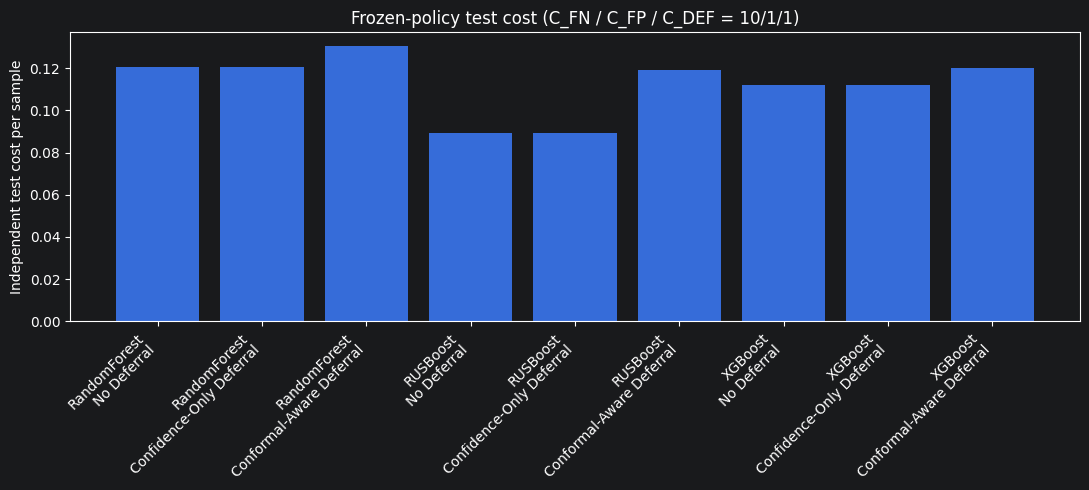

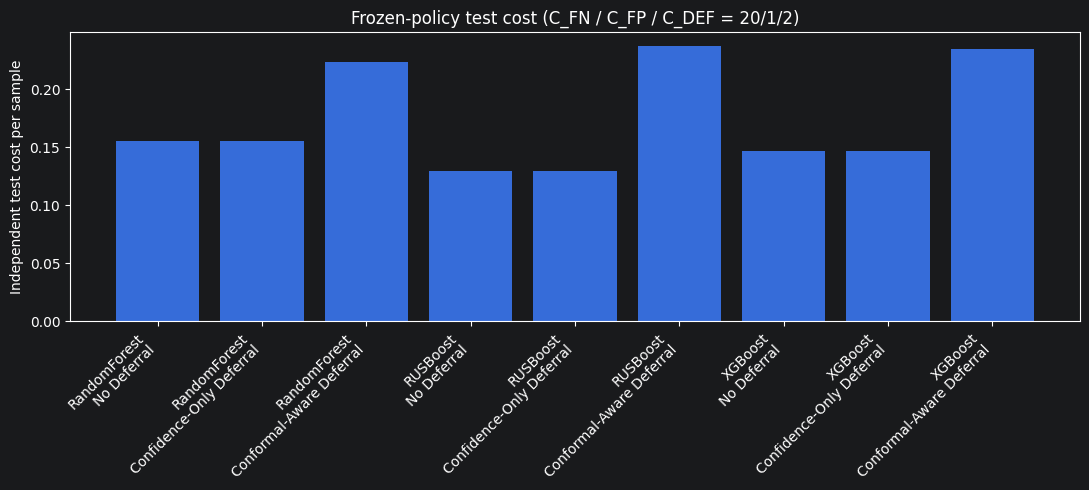

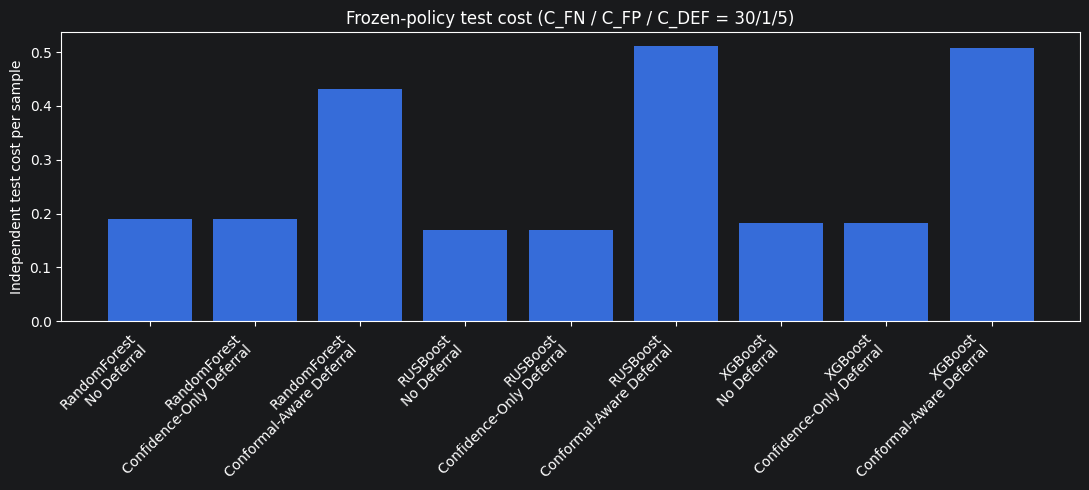

In [8]:
for scenario, group in best_policy_df.groupby("cost_scenario"):
    plt.figure(figsize=(11, 5))
    x_labels = group["model"] + "\n" + group["policy"]
    plt.bar(x_labels, group["cost_per_sample"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Independent test cost per sample")
    plt.title(f"Frozen-policy test cost (C_FN / C_FP / C_DEF = {scenario})")
    plt.tight_layout()
    plot_path = OUTPUT_DIR / f"test_cost_per_sample_{scenario.replace('/', '_')}.png"
    plt.savefig(plot_path, dpi=200, bbox_inches="tight")
    plt.show()

## 7. Plot: tuning cost–coverage search (NOT independent test curve)

These search points come from the policy-tuning partition. Test outcomes are shown separately as frozen-policy points, not as a test-optimized frontier.

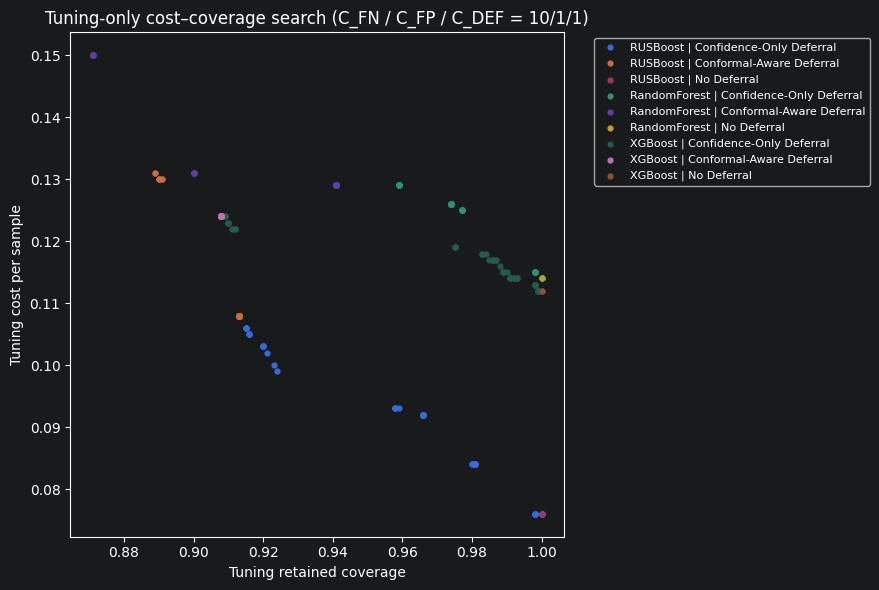

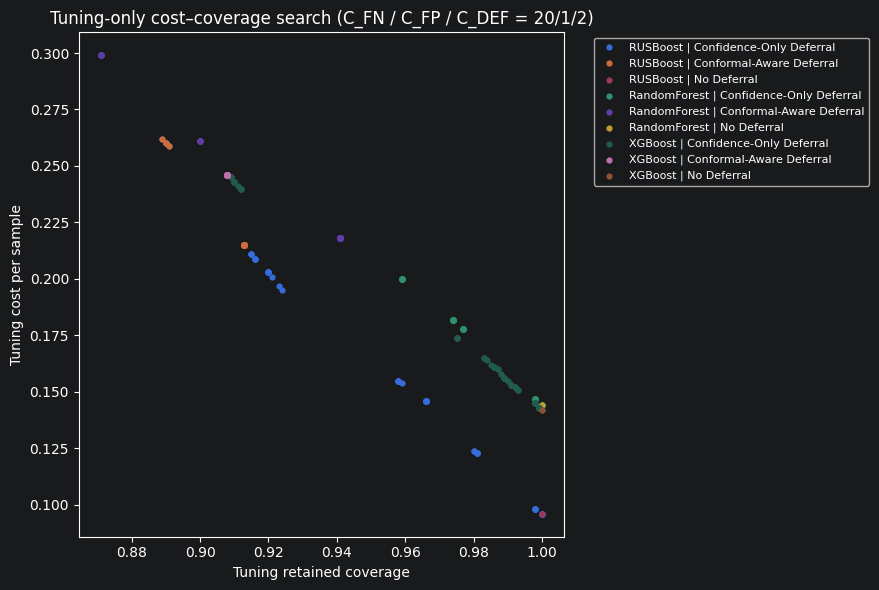

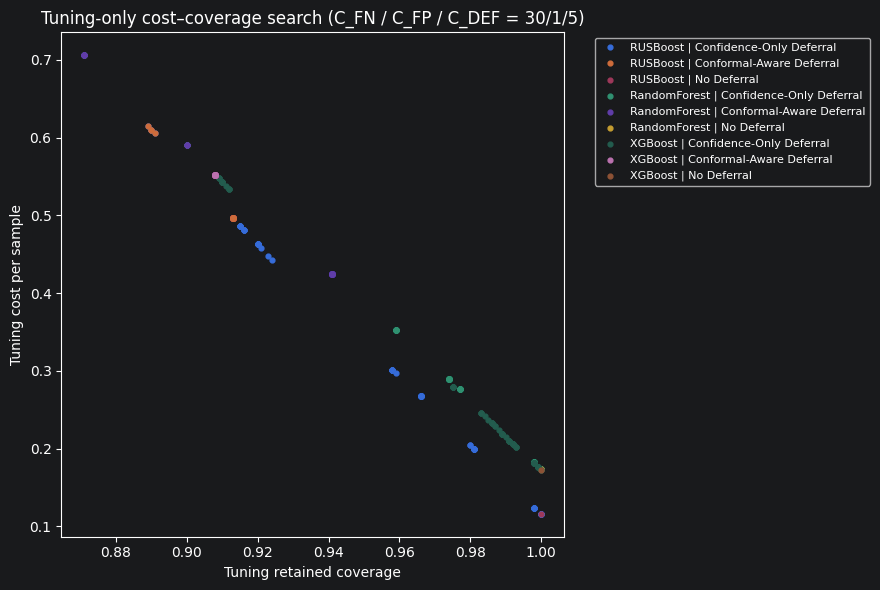

In [9]:
for scenario, group in policy_search_df.groupby("cost_scenario"):
    plt.figure(figsize=(9, 6))
    for (model, policy), part in group.groupby(["model", "policy"]):
        plt.scatter(part["coverage"], part["cost_per_sample"], label=f"{model} | {policy}", s=12)
    plt.xlabel("Tuning retained coverage")
    plt.ylabel("Tuning cost per sample")
    plt.title(f"Tuning-only cost–coverage search (C_FN / C_FP / C_DEF = {scenario})")
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"tuning_coverage_vs_cost_{scenario.replace('/', '_')}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 8. Plot: independent test deferred fraction

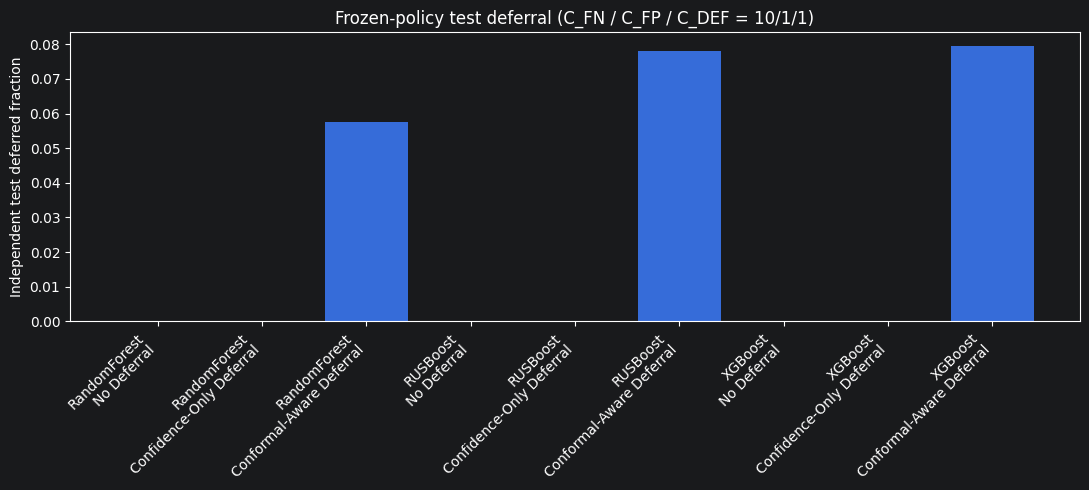

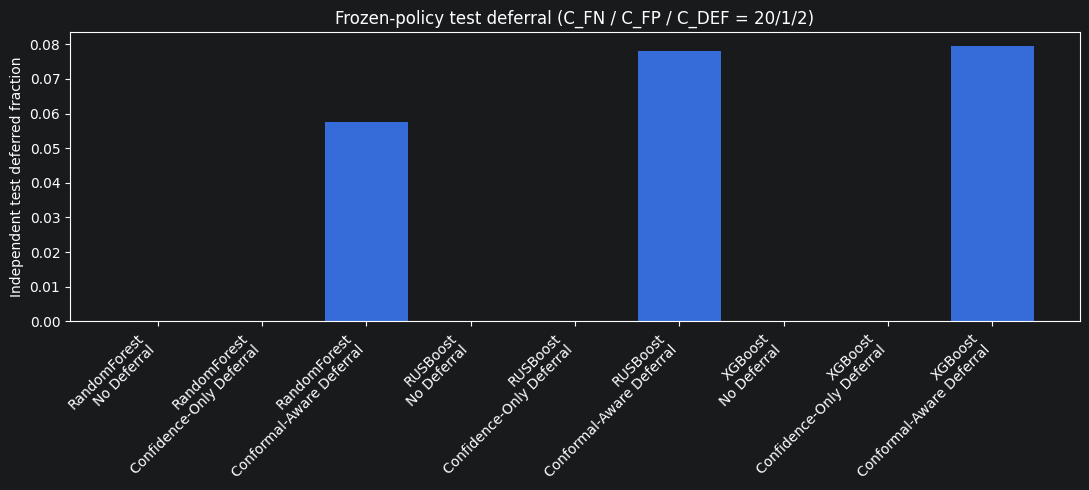

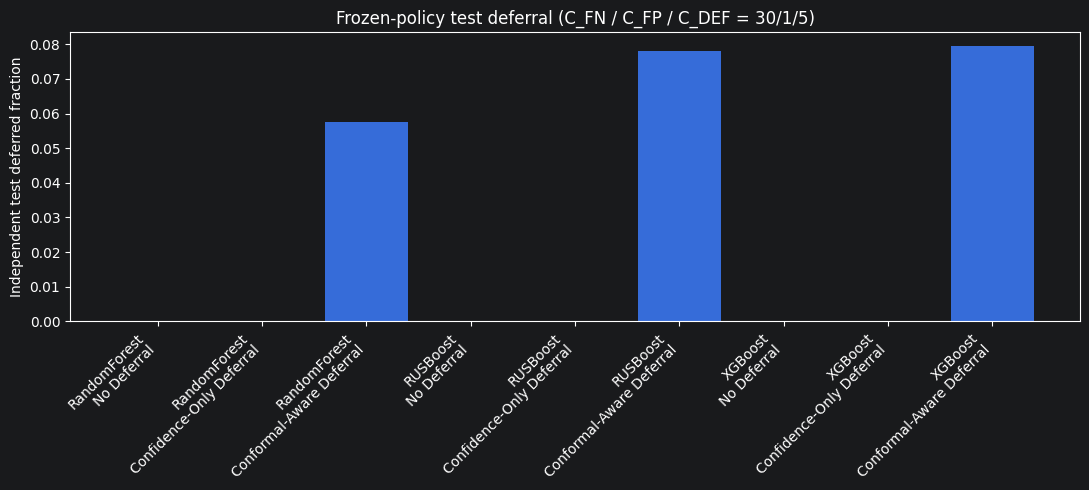

In [10]:
for scenario, group in best_policy_df.groupby("cost_scenario"):
    plt.figure(figsize=(11, 5))
    x_labels = group["model"] + "\n" + group["policy"]
    plt.bar(x_labels, group["deferred_fraction"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Independent test deferred fraction")
    plt.title(f"Frozen-policy test deferral (C_FN / C_FP / C_DEF = {scenario})")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"test_deferred_fraction_{scenario.replace('/', '_')}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 9. Compare confidence-only and conformal-aware deferral on independent test data

No assertion of superiority is made; the corrected test outcomes determine the conclusion.

In [11]:
innovation_comparison = best_policy_df[
    best_policy_df["policy"].isin(["Confidence-Only Deferral", "Conformal-Aware Deferral"])
].copy()
innovation_comparison.to_csv(OUTPUT_DIR / "innovation_confidence_vs_conformal_aware.csv", index=False)
display(innovation_comparison[["cost_scenario", "model", "policy", "cost_per_sample",
                               "retained_error", "retained_recall", "deferred_fraction"]])

,cost_scenario,model,policy,cost_per_sample,retained_error,retained_recall,deferred_fraction
1,10/1/1,RandomForest,Confidence-Only Deferral,0.1205,0.089000,0.897059,0.0000
2,10/1/1,RandomForest,Conformal-Aware Deferral,0.1305,0.044032,0.854167,0.0575
4,20/1/2,RandomForest,Confidence-Only Deferral,0.1555,0.089000,0.897059,0.0000
5,20/1/2,RandomForest,Conformal-Aware Deferral,0.2230,0.044032,0.854167,0.0575
7,30/1/5,RandomForest,Confidence-Only Deferral,0.1905,0.089000,0.897059,0.0000
8,30/1/5,RandomForest,Conformal-Aware Deferral,0.4305,0.044032,0.854167,0.0575
10,10/1/1,RUSBoost,Confidence-Only Deferral,0.0895,0.053500,0.882353,0.0000
11,10/1/1,RUSBoost,Conformal-Aware Deferral,0.1190,0.005423,0.555556,0.0780
13,20/1/2,RUSBoost,Confidence-Only Deferral,0.1295,0.053500,0.882353,0.0000
14,20/1/2,RUSBoost,Conformal-Aware Deferral,0.2370,0.005423,0.555556,0.0780


## 10. Interpretation safeguards

- All cost labels use **(C_FN / C_FP / C_DEF)**; the 30/1/5 scenario changes both false-negative and deferral costs compared with 20/1/2.
- The policy-selection data and independent test data must have disjoint row IDs.
- Empirical marginal conformal coverage is distinct from retained coverage after deferral.
- An empty conformal set is not the same as a two-label ambiguous set.
- Report corrected outcomes even if they are worse than historical results.
- The repeated-CV correction and publication claims review are separate later checkpoints.

In [12]:
print("Fix 3.2 complete. Test labels were not passed to tune_policy.")
print("Independent test comparison:", OUTPUT_DIR / "best_policy_comparison.csv")
print("Source run metadata:", OUTPUT_DIR / "evaluation_manifest.json")

Fix 3.2 complete. Test labels were not passed to tune_policy.
corrected_policy_outputs/20261115T190522567778Z_policy_eval/best_policy_comparison.csv
corrected_policy_outputs/20261115T190522567778Z_policy_eval/evaluation_manifest.json
